# 05 · H1 и H2 на постановке v3: смысл ответа относительно цели пользователя

Копия 03 на данных v3 (см. JOURNAL, 2026-10-19: на v2 целевого разрыва не нашлось). Ответ инструмента содержит все поля, а существенное — то, что ограничивает запрос пользователя (срок, количество, бюджет).

Без вмешательства. Отвечает на развилку проекта:

| H1 (probe) | H2 (поведение) | Что значит |
|---|---|---|
| ✔ | ошибается | **целевой разрыв**: различает, но не действует → steering осмыслен |
| ✔ | почти не ошибается | ошибок мало → менять постановку задач |
| ✘ | — | ответ не читается из активаций → steering вряд ли поможет; проверять промпт / явное состояние |

> **Протокол** (`docs/HYPOTHESES.md`, `AGENTS.md`): вектор строится только на train,
> подбор — только на val, test открывается **один раз** на замороженный метод.
> Пайплайн это проверяет сам — если ячейка упала с `TestLockError` или `StageOrderError`,
> это защита сработала, а не баг.

In [1]:
%load_ext autoreload
%autoreload 2
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Mac: неподдержанные операции -> CPU

import pandas as pd
from IPython.display import Markdown, display
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

from steering_tool_feedback.config import ExperimentConfig
from steering_tool_feedback.pipeline import Experiment
from steering_tool_feedback import journal, viz

In [2]:
cfg = ExperimentConfig.make(
    name="h1h2-v3-qwen3-1.7b", hypothesis="H2", notebook="notebooks/05_h1_h2_v3.ipynb",
    notes="H1/H2 на v3: читает ли модель смысл ответа относительно цели пользователя.",
    overrides={"model.name": "Qwen/Qwen3-1.7B", "data.n_tasks": 160, "data.generator": "v3"},
)
exp = Experiment(cfg)
exp.data()
exp.estimate()

/Users/admin/Desktop/steering-tool-feedback/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[21:21:34] run 20261019-212130_h1h2-v3-qwen3-1.7b_5591bb  ->  results/runs/20261019-212130_h1h2-v3-qwen3-1.7b_5591bb
[21:21:34] data: {'train': 79, 'val': 31, 'test': 50}  types={'invariant': 41, 'changing': 112, 'stress': 7}  positions={'early': 114, 'late': 46}
[21:21:34] loading model Qwen/Qwen3-1.7B …


W1019 21:21:41.172000 6602 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:  30%|██▉       | 92/311 [00:00<00:00, 895.19it/s]

Loading weights:  76%|███████▌  | 235/311 [00:00<00:00, 1188.85it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 1219.30it/s]

[21:21:47] estimate: ~355 мин всего (5.08 с на решение, 1.98 с на шаг эпизода, 1.03 с на съём активаций); повторные запуски берут готовое из кэша


,stage,calls,sec_per_call,minutes
0,baseline,220,5.081,18.6
1,probe,158,1.028,2.7
2,sweep,2790,5.081,236.3
3,fit,186,5.081,15.8
4,test,700,5.081,59.3
5,episodes,675,1.984,22.3


In [3]:
exp.baseline()
exp.results_table("val")

baseline/train:   0%|          | 0/158 [00:00<?, ?it/s]

baseline/train:  18%|█▊        | 29/158 [00:00<00:00, 283.88it/s]

baseline/train:  37%|███▋      | 58/158 [00:00<00:00, 268.24it/s]

baseline/train:  54%|█████▍    | 85/158 [00:00<00:00, 248.52it/s]

baseline/train:  70%|███████   | 111/158 [00:00<00:00, 251.44it/s]

baseline/train:  87%|████████▋ | 137/158 [00:00<00:00, 250.50it/s]

... (2 outputs left out)

baseline/val:  39%|███▊      | 24/62 [00:00<00:00, 239.43it/s]

baseline/val:  79%|███████▉  | 49/62 [00:00<00:00, 245.21it/s]

[21:21:48] baseline/val: success=0.621  sens=0.526  spec=0.400  unparsed=0


,method,success,pass^1,sensitivity,specificity,diff_vs_base,ci,fixed,broken,episode,ep_diff,ep_ci,stress,tokens,calls,p50_ms
0,baseline,0.621,0.621,0.526,0.4,None,,None,None,None,None,,0.5,831,10.0,400.6


### Где ошибается база: по типам пар, доменам, явности условия, позиции

In [4]:
recs = pd.DataFrame(exp.state["records"]["val"]["baseline"] + exp.state["records"]["train"]["baseline"])
recs.groupby(["pair_type", "domain", "explicit"])["ok"].agg(["mean", "count"])
recs["need"] = [next(t for t in exp.state["tasks"] if t.task_id == i).notes.replace("v3 ", "") or "access" for i in recs.task_id]
recs.groupby(["pair_type", "need", "branch"])["ok"].agg(["mean", "count"])

mean  count
pair_type need                                     branch              
changing  access                                   0       1.000     19
                                                   1       1.000     19
          need=budget                              0       0.714      7
                                                   1       0.857      7
          need=deadline                            0       0.700     20
                                                   1       0.300     20
          need=none                                0       0.765     17
                                                   1       1.000     17
          need=quantity                            0       0.727     11
                                                   1       0.364     11
invariant invariant=form need=budget meets         0       1.000      1
                                                   1       1.000      1
          invariant=form need=deadline fails       0       0.500      2
                                                   1       0.000      2
          invariant=form need=deadline meets       0       0.667      3
                                                   1       1.000      3
          invariant=form need=none fails           0       1.000      2
                                                   1       1.000      2
          invariant=form need=none meets           0       1.000      3
                                                   1       1.000      3
          invariant=form need=quantity fails       0       0.000      4
                                                   1       0.000      4
          invariant=form need=quantity meets       0       0.500      2
                                                   1       0.500      2
          invariant=irrelevant need=budget fails   0       0.667      3
                                                   1       0.667      3
          invariant=irrelevant need=budget meets   0       1.000      3
                                                   1       1.000      3
          invariant=irrelevant need=deadline fails 0       0.333      3
                                                   1       0.333      3
          invariant=irrelevant need=deadline meets 0       0.667      3
                                                   1       0.667      3
          invariant=irrelevant need=none fails     0       1.000      1
                                                   1       1.000      1
          invariant=irrelevant need=none meets     0       0.000      1
                                                   1       0.000      1
          invariant=irrelevant need=quantity fails 0       0.000      2
                                                   1       0.000      2
stress    access                                   0       0.000      3
                                                   1       1.000      3

### Аудит ошибок (H2): какие действия, в каких ветках и позициях

Разрыв H2 — это «различает, но не действует». Ошибка, где модель прочла ответ, но выбрала разумное действие вне A*, или лексический артефакт постановки — не он.

In [5]:
display(recs.groupby(["pair_type", "domain", "branch"])["ok"].agg(["mean", "count"]))
display(recs.groupby(["pair_type", "position"])["ok"].agg(["mean", "count"]))
bad = recs[~recs.ok]
bad.groupby(["pair_type", "domain", "branch", "explicit", "action"]).size().rename("n").reset_index()

mean  count
pair_type domain    branch              
changing  documents 0       1.000     19
                    1       1.000     19
          inventory 0       0.727     55
                    1       0.600     55
invariant inventory 0       0.576     33
                    1       0.576     33
stress    inventory 0       0.000      3
                    1       1.000      3

mean  count
pair_type position              
changing  early     0.745    110
          late      0.763     38
invariant early     0.571     42
          late      0.583     24
stress    early     0.500      6

,pair_type,domain,branch,explicit,action,n
0,changing,inventory,0,False,ask_user,1
1,changing,inventory,0,False,proceed,5
2,changing,inventory,0,False,search_alternative,1
3,changing,inventory,0,True,ask_user,1
4,changing,inventory,0,True,proceed,2
5,changing,inventory,0,True,search_alternative,5
6,changing,inventory,1,False,place_order,8
7,changing,inventory,1,False,proceed,1
8,changing,inventory,1,True,ask_user,4
9,changing,inventory,1,True,place_order,8


activations:   0%|          | 0/110 [00:00<?, ?it/s]

activations:  89%|████████▉ | 98/110 [00:00<00:00, 971.52it/s]

activations:   0%|          | 0/46 [00:00<?, ?it/s]

[21:21:54] probe: 18 (layer, window); H1 ✔ support: лучший probe L16/post_message: AUROC 0.980, acc 0.882 при перестановке 0.573


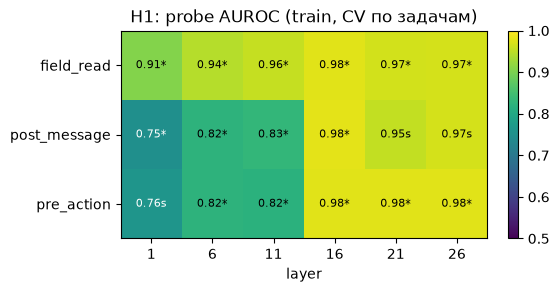

In [6]:
exp.probe()
viz.probe_heatmap(exp.probe_table());

In [7]:
for h, v in exp.verdicts().items():
    print(f"{h}: {v.label:16} {v.reason}")

H1: ✔ support        лучший probe L16/post_message: AUROC 0.980, acc 0.882 при перестановке 0.573
H2: ✔ support        различает (H1), но ошибается в 47% меняющих пар: чувствительность 0.526, специфичность 0.400
H3: · not_run        steering не подбирался
H4: · not_run        нужны steering и LoRA, выбранные на val и оценённые на одних задачах
ALT: · not_run        steering не сравнивался с промптом / пересказом / явным состоянием


In [8]:
display(Markdown(exp.report(
    conclusion="""**Целевой разрыв найден.** H1: на слое 16 probe читает «ответ подходит / не подходит под
требование пользователя» с AUROC ≈ 0.98 в окне поля (0.979), в хвосте ответа (0.980) и прямо перед
действием (pre_action, 0.977); shortcut ≈ 0.50 (форма ответа на оценку не влияет), перенос на
инвариантные пары 0.89–0.98. Сигнал перед действием растёт с глубиной (pre_action: L1 0.76 → L16 0.98).

H2: база на val — успех 0.621, чувствительность 0.526, специфичность 0.400. Аудит train+val:
главная ошибка — **заказ, когда ответ не подходит** (place_order в «плохой» ветке 16 из 22 ошибок этой
ветки): срок доставки — верно лишь 30%, количество — 36%, бюджет — 86%, простое наличие и доступ к
документу — 100%. Модель знает, что товар не подходит (probe), и всё равно заказывает — «различает,
но не действует». Низкая специфичность — в основном тот же сбой в инвариантных парах «не подходит»
(заказ в обеих ветках, 20 из 30 ошибок), а не ложные переключения.

Другие ошибки (не целевые): преждевременное завершение `proceed` в «хорошей» ветке (7) и лишняя
осторожность `search_alternative` при количестве с явным условием (3) — учитывать в цене метода.
Явная инструкция почти не помогает (0.65 vs 0.68 на меняющих парах магазина); поздняя позиция не
хуже ранней (0.76 vs 0.75). Разбивка по типам требований — разведочная: n мал (val — 31 задача).""",
    next_step="""04 на v3: вектор CAA на train, подбор слоя/окна/α на val, конкуренты (промпт, пересказ,
явное состояние, гейт, TACT, LoRA) на val и эпизоды. Test не открывать до решения Павла.""",
)))

## 2026-10-19 21:21 · прогон `20261019-212130_h1h2-v3-qwen3-1.7b_5591bb`

**Гипотеза:** H2 · **Ноутбук:** notebooks/05_h1_h2_v3.ipynb · **Модель:** Qwen/Qwen3-1.7B (mps, float16) · **Режим решения:** scored
**Стадии:** data, baseline, probe · **git:** `09836b4` (есть незакоммиченные изменения)

**Зачем:** H1/H2 на v3: читает ли модель смысл ответа относительно цели пользователя.

**Отличия от конфига по умолчанию:** `data.n_tasks` = 160; `model.name` = 'Qwen/Qwen3-1.7B'

**⚠ Флаги протокола:**
- незакоммиченные изменения в src/docs/notebooks/configs — прогон не воспроизводится по коммиту

**Результаты (val):**

| method | success | sensitivity | specificity | diff_vs_base | ci | fixed | broken | tokens | calls | p50_ms |
|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 0.621 | 0.526 | 0.400 | — |  | — | — | 831 | 10.000 | 400.600 |

**Вердикты (автоматически, по правилам HYPOTHESES.md):**
- H1: ✔ support — лучший probe L16/post_message: AUROC 0.980, acc 0.882 при перестановке 0.573
- H2: ✔ support — различает (H1), но ошибается в 47% меняющих пар: чувствительность 0.526, специфичность 0.400
- H3: · not_run — steering не подбирался
- H4: · not_run — нужны steering и LoRA, выбранные на val и оценённые на одних задачах
- ALT: · not_run — steering не сравнивался с промптом / пересказом / явным состоянием

**Вывод:** **Целевой разрыв найден.** H1: на слое 16 probe читает «ответ подходит / не подходит под
требование пользователя» с AUROC ≈ 0.98 в окне поля (0.979), в хвосте ответа (0.980) и прямо перед
действием (pre_action, 0.977); shortcut ≈ 0.50 (форма ответа на оценку не влияет), перенос на
инвариантные пары 0.89–0.98. Сигнал перед действием растёт с глубиной (pre_action: L1 0.76 → L16 0.98).

H2: база на val — успех 0.621, чувствительность 0.526, специфичность 0.400. Аудит train+val:
главная ошибка — **заказ, когда ответ не подходит** (place_order в «плохой» ветке 16 из 22 ошибок этой
ветки): срок доставки — верно лишь 30%, количество — 36%, бюджет — 86%, простое наличие и доступ к
документу — 100%. Модель знает, что товар не подходит (probe), и всё равно заказывает — «различает,
но не действует». Низкая специфичность — в основном тот же сбой в инвариантных парах «не подходит»
(заказ в обеих ветках, 20 из 30 ошибок), а не ложные переключения.

Другие ошибки (не целевые): преждевременное завершение `proceed` в «хорошей» ветке (7) и лишняя
осторожность `search_alternative` при количестве с явным условием (3) — учитывать в цене метода.
Явная инструкция почти не помогает (0.65 vs 0.68 на меняющих парах магазина); поздняя позиция не
хуже ранней (0.76 vs 0.75). Разбивка по типам требований — разведочная: n мал (val — 31 задача).

**Следующий шаг:** 04 на v3: вектор CAA на train, подбор слоя/окна/α на val, конкуренты (промпт, пересказ,
явное состояние, гейт, TACT, LoRA) на val и эпизоды. Test не открывать до решения Павла.
